In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os 
folder=r"C:/Users/Rajesh Srivastav/Desktop/data_analyst/New folder"
os.listdir(folder)

['.ipynb_checkpoints',
 'Delinquency_prediction_dataset.csv',
 'Delinquency_prediction_dataset.xlsx',
 'EDA_quaries.sql',
 'EDA_SummaryReport_Template.docx',
 'Imputation_Guide_Handout.docx',
 'Tata_Data_Analytics_Glossary (1).docx',
 'Untitled.ipynb',
 'Updated_Dataset_Description_Guide_copy.pdf',
 'update_dateset(after_sql_quaries).csv',
 '~$A_SummaryReport_Template.docx',
 '~$putation_Guide_Handout.docx']

In [21]:
df=pd.read_csv(r"C:\Users\Rajesh Srivastav\Desktop\data_analyst\New folder\update_dateset(after_sql_quaries).csv",sep=",")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           500 non-null    object 
 1   Age                   500 non-null    int64  
 2   Income                500 non-null    int64  
 3   Credit_Score          500 non-null    int64  
 4   Credit_Utilization    500 non-null    float64
 5   Missed_Payments       500 non-null    int64  
 6   Delinquent_Account    500 non-null    int64  
 7   Loan_Balance          500 non-null    int64  
 8   Debt_to_Income_Ratio  500 non-null    float64
 9   Employment_Status     500 non-null    object 
 10  Account_Tenure        500 non-null    int64  
 11  Credit_Card_Type      500 non-null    object 
 12  Location              500 non-null    object 
 13  Month_1               500 non-null    object 
 14  Month_2               500 non-null    object 
 15  Month_3               5

,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,165580,398,0.390502,3,0,16310,0.317396,Employed,18,Student,Los Angeles,Late,Late,Missed,Late,Missed,Late
1,CUST0002,69,100999,493,0.312444,6,1,17401,0.196093,Self_Employed,0,Standard,Phoenix,Missed,Missed,Late,Missed,On-time,On-time
2,CUST0003,46,188416,500,0.359930,0,0,13761,0.301655,Self_Employed,1,Platinum,Chicago,Missed,Late,Late,On-time,Missed,Late
3,CUST0004,32,101672,413,0.371400,3,0,88778,0.264794,Unemployed,15,Platinum,Phoenix,Late,Missed,Late,Missed,Late,Late
4,CUST0005,60,38524,487,0.234716,2,0,13316,0.510583,Self_Employed,11,Standard,Phoenix,Missed,On-time,Missed,Late,Late,Late


In [25]:
#convert text to number(0 -ontime ,1- LATE,2- missed
month_map={'Late':1,'Missed':2,'On-time':0}
month_cols=['Month_1','Month_2','Month_3','Month_4','Month_5','Month_6']
for col in month_cols:
    df[col+'_num']=df[col].map(month_map)
# Total payment severity Score of 6 months
df['payment_severity_Score']=df[[c + '_num' for c in month_cols]].sum(axis=1)
print(df[['Customer_ID','Month_1','Month_1_num','payment_severity_Score',]].head())


  Customer_ID Month_1  Month_1_num  payment_severity_Score
0    CUST0001    Late            1                       8
1    CUST0002  Missed            2                       7
2    CUST0003  Missed            2                       7
3    CUST0004    Late            1                       8
4    CUST0005  Missed            2                       7


Correlation with delinquent_account:
 Delinquent_Account        1.000000
Income                    0.043991
Credit_Score              0.034733
Credit_Utilization        0.034557
Debt_to_Income_Ratio      0.034386
Age                       0.022508
Loan_Balance             -0.005438
payment_severity_Score   -0.014806
Missed_Payments          -0.026478
Account_Tenure           -0.039829
Name: Delinquent_Account, dtype: float64


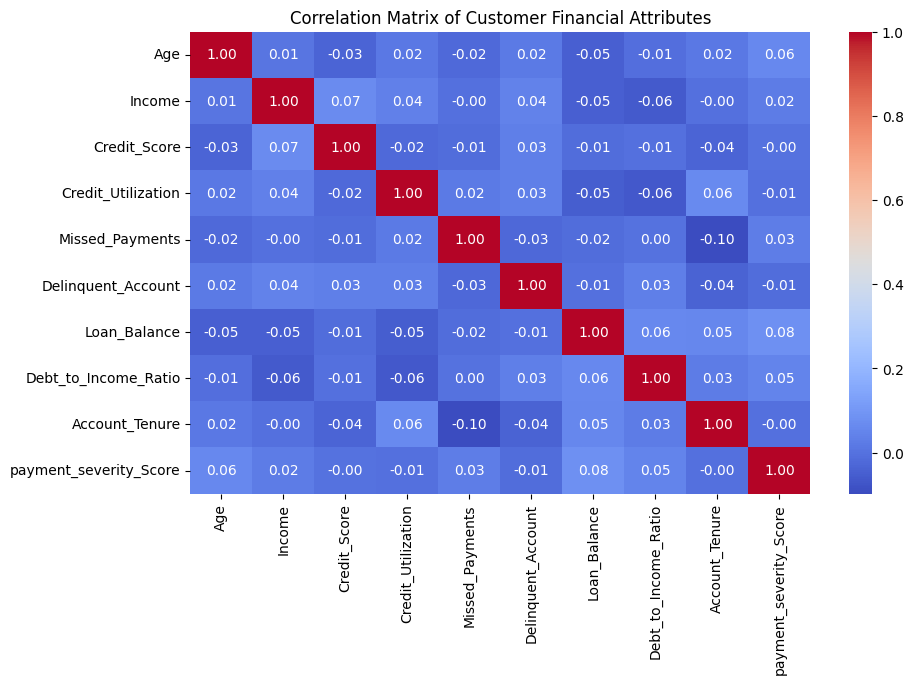

In [28]:
# check correlation of numerical columns
num_cols =['Age','Income','Credit_Score','Credit_Utilization','Missed_Payments','Delinquent_Account','Loan_Balance','Debt_to_Income_Ratio','Account_Tenure','payment_severity_Score']
corr_matrix =df[num_cols].corr()
print('Correlation with delinquent_account:\n',corr_matrix['Delinquent_Account'].sort_values(ascending=False))
#Plot correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix of Customer Financial Attributes')
plt.show()

In [26]:
print(df.columns.tolist())

['Customer_ID', 'Age', 'Income', 'Credit_Score', 'Credit_Utilization', 'Missed_Payments', 'Delinquent_Account', 'Loan_Balance', 'Debt_to_Income_Ratio', 'Employment_Status', 'Account_Tenure', 'Credit_Card_Type', 'Location', 'Month_1', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_1_num', 'Month_2_num', 'Month_3_num', 'Month_4_num', 'Month_5_num', 'Month_6_num', 'payment_severity_Score']


In [29]:
df.to_csv('Final_cleaned_dataset.csv',index=False)
print("Final file successfully")

Final file successfully
